In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler

In [ ]:
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target

In [ ]:
df = pd.DataFrame(data=diabetes.data,
                  columns=diabetes.feature_names)

In [ ]:
df['target'] = diabetes.target

print(df.head())

print("\nDataFrame Info:")
print(df.info())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  

DataFrame Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null  

In [ ]:
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [ ]:
df.describe()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [ ]:
df.shape

(442, 11)

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

Optimal number of neighbors (K): 18


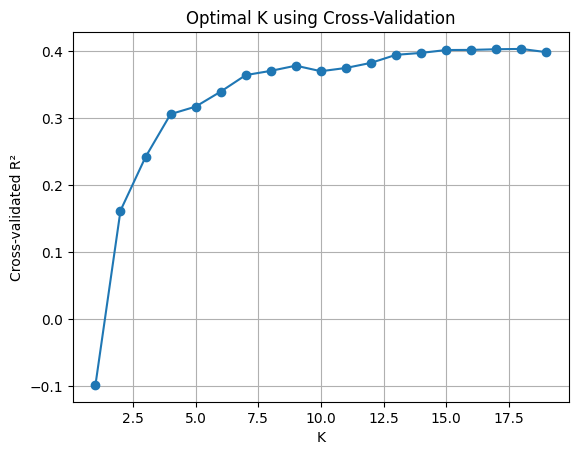

In [ ]:
from sklearn.model_selection import cross_val_score
k_range = range(1, 20)
cv_scores = []

for k in k_range:
    knn = KNeighborsRegressor(n_neighbors=k)
    scores = cross_val_score(knn, X_train, y_train, cv=5, scoring='r2')
    cv_scores.append(scores.mean())

optimal_k = k_range[np.argmax(cv_scores)]
print(f"Optimal number of neighbors (K): {optimal_k}")

plt.plot(k_range, cv_scores, marker='o')
plt.xlabel('K')
plt.ylabel('Cross-validated R²')
plt.title('Optimal K using Cross-Validation')
plt.grid(True)
plt.show()

In [ ]:
knn_regressor = KNeighborsRegressor(optimal_k)
knn_regressor.fit(X_train, y_train)

KNeighborsRegressor(n_neighbors=18)

In [ ]:
y_pred = knn_regressor.predict(X_test)

In [ ]:
results_df = pd.DataFrame({
    'Actual': y_test,
    'Predicted': y_pred
})

print("\nComparison of Actual vs Predicted values:")
print(results_df.head(30))


Comparison of Actual vs Predicted values:
    Actual   Predicted
0    219.0  155.611111
1     70.0  157.555556
2    202.0  151.833333
3    230.0  229.333333
4    111.0  167.333333
5     84.0  129.388889
6    242.0  242.888889
7    272.0  179.444444
8     94.0   85.222222
9     96.0  123.166667
10    94.0  125.000000
11   252.0  130.833333
12    99.0  105.666667
13   297.0  198.833333
14   135.0  104.333333
15    67.0  104.833333
16   295.0  230.555556
17   264.0  224.888889
18   170.0  159.777778
19   275.0  197.611111
20   310.0  184.000000
21    64.0  115.333333
22   128.0   96.444444
23   232.0  198.722222
24   129.0  142.055556
25   118.0  137.833333
26   263.0  179.222222
27    77.0  147.166667
28    48.0   93.777778
29   107.0  150.222222


In [ ]:
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f'Mean Squared Error: {mse}')
print(f'R-squared: {r2}')

Mean Squared Error: 3083.9003329171865
R-squared: 0.41792902897116346


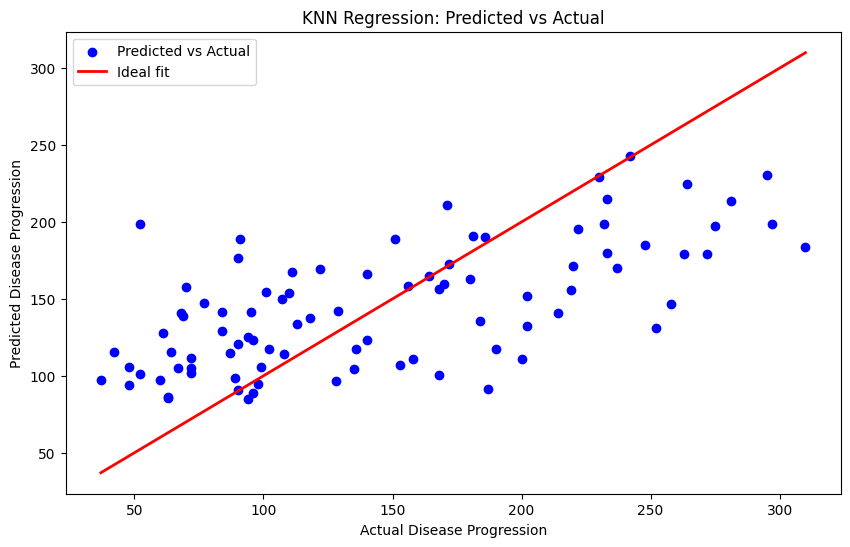

In [ ]:
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, color='blue', label='Predicted vs Actual')
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], color='red', linewidth=2, label='Ideal fit')
plt.title('KNN Regression: Predicted vs Actual')
plt.xlabel('Actual Disease Progression')
plt.ylabel('Predicted Disease Progression')
plt.legend()
plt.show()

In [ ]:
print("\nEnter the 10 feature values for the new patient:")

age = float(input("Age: "))
sex = float(input("Sex (1 = male, 0 = female): "))
bmi = float(input("Body Mass Index (BMI): "))
bp = float(input("Average Blood Pressure: "))
s1 = float(input("S1 (TC - Total Serum Cholesterol): "))
s2 = float(input("S2 (LDL - Low-Density Lipoproteins): "))
s3 = float(input("S3 (HDL - High-Density Lipoproteins): "))
s4 = float(input("S4 (TCH - Total Cholesterol / HDL): "))
s5 = float(input("S5 (LTG - Possibly log of serum triglycerides): "))
s6 = float(input("S6 (GLU - Blood Sugar Level): "))

user_input = np.array([[age, sex, bmi, bp, s1, s2, s3, s4, s5, s6]])

scaler = StandardScaler()
scaler.fit(X_train)

user_input_scaled = scaler.transform(user_input)
prediction = knn_regressor.predict(user_input_scaled)
print(f"\nPredicted Disease Progression: {prediction[0]:.2f}")


Enter the 10 feature values for the new patient:
Age: 50
Sex (1 = male, 0 = female): 1
Body Mass Index (BMI): 20
Average Blood Pressure: 90
S1 (TC - Total Serum Cholesterol): 20
S2 (LDL - Low-Density Lipoproteins): 20
S3 (HDL - High-Density Lipoproteins): 20
S4 (TCH - Total Cholesterol / HDL): 0
S5 (LTG - Possibly log of serum triglycerides): 20
S6 (GLU - Blood Sugar Level): 20

Predicted Disease Progression: 228.06
